In [2]:
import torch

data = torch.load(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/target_hidden_states.pt",
    map_location="cpu",
)

print(data.keys())

dict_keys(['image_paths', 'conditions', 'num_distractors', 'trials', 'image_width', 'image_height', 'target_x', 'target_y', 'target_x_px', 'target_y_px', 'bbox_left', 'bbox_top', 'bbox_right', 'bbox_bottom', 'raw_h', 'raw_w', 'token_h', 'token_w', 'merge_size', 'raw_patch_x', 'raw_patch_y', 'target_token_x', 'target_token_y', 'target_token_idx', 'bbox_token_indices', 'window3x3_indices', 'center_token_hidden', 'bbox_mean_hidden', 'window3x3_mean_hidden', 'bbox_hidden', 'window3x3_hidden'])


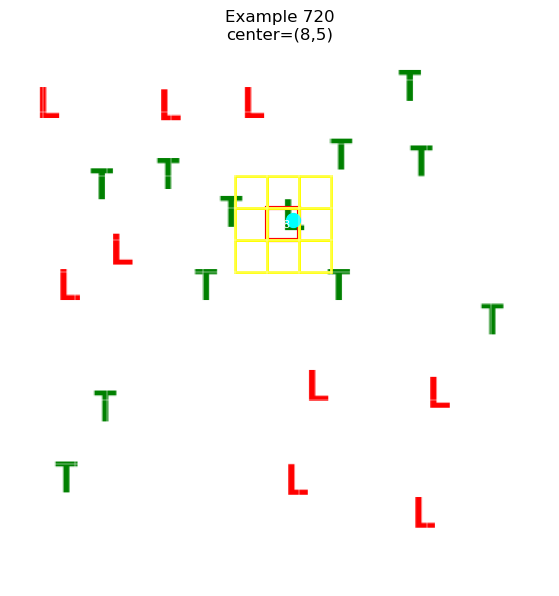

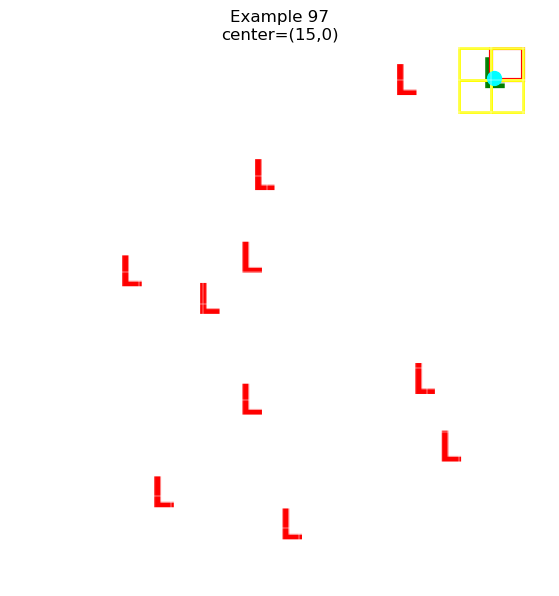

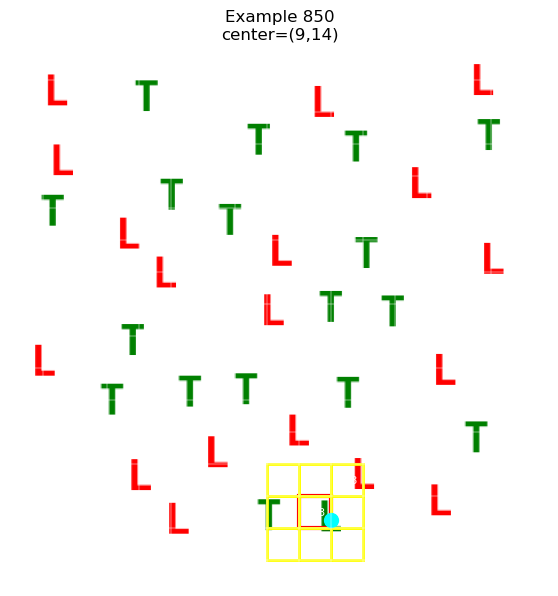

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import numpy as np

IMAGE_SIZE = 448
TOKEN_GRID_SIZE = 16
TOKEN_SIZE = IMAGE_SIZE / TOKEN_GRID_SIZE

# 3 random exmaples

rng = np.random.default_rng(42)

indices = rng.choice(
    len(data["image_paths"]),
    size=min(3, len(data["image_paths"])),
    replace=False,
)

for i in indices:

    path = data["image_paths"][i]

    image = Image.open(path).convert("RGB")

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.imshow(image)


    for x in range(TOKEN_GRID_SIZE + 1):
        ax.axvline(
            x * TOKEN_SIZE,
            color="white",
            alpha=0.25,
        )

    for y in range(TOKEN_GRID_SIZE + 1):
        ax.axhline(
            y * TOKEN_SIZE,
            color="white",
            alpha=0.25,
        )

    # --------------------------------------------------
    # center token
    # --------------------------------------------------

    tx = int(data["target_token_x"][i])
    ty = int(data["target_token_y"][i])

    rect = patches.Rectangle(
        (
            tx * TOKEN_SIZE,
            ty * TOKEN_SIZE,
        ),
        TOKEN_SIZE,
        TOKEN_SIZE,
        linewidth=3,
        edgecolor="red",
        facecolor="none",
    )

    ax.add_patch(rect)



    for y in range(
        max(0, ty - 1),
        min(TOKEN_GRID_SIZE, ty + 2),
    ):
        for x in range(
            max(0, tx - 1),
            min(TOKEN_GRID_SIZE, tx + 2),
        ):

            rect = patches.Rectangle(
                (
                    x * TOKEN_SIZE,
                    y * TOKEN_SIZE,
                ),
                TOKEN_SIZE,
                TOKEN_SIZE,
                linewidth=2,
                edgecolor="yellow",
                facecolor="none",
            )

            ax.add_patch(rect)

            idx = (
                y * TOKEN_GRID_SIZE
                + x
            )

            ax.text(
                x * TOKEN_SIZE
                + TOKEN_SIZE / 2,
                y * TOKEN_SIZE
                + TOKEN_SIZE / 2,
                str(idx),
                color="white",
                fontsize=8,
                ha="center",
                va="center",
            )



    if "target_x" in data:

        px = (
            (
                data["target_x"][i].item()
                - 0.5
            )
            / 9.0
            * IMAGE_SIZE
        )

        py = IMAGE_SIZE - (
            (
                data["target_y"][i].item()
                - 0.5
            )
            / 9.0
            * IMAGE_SIZE
        )

        ax.scatter(
            px,
            py,
            c="cyan",
            s=100,
            label="target center",
        )

    ax.set_title(
        f"Example {i}\n"
        f"center=({tx},{ty})"
    )

    ax.axis("off")
    plt.show()

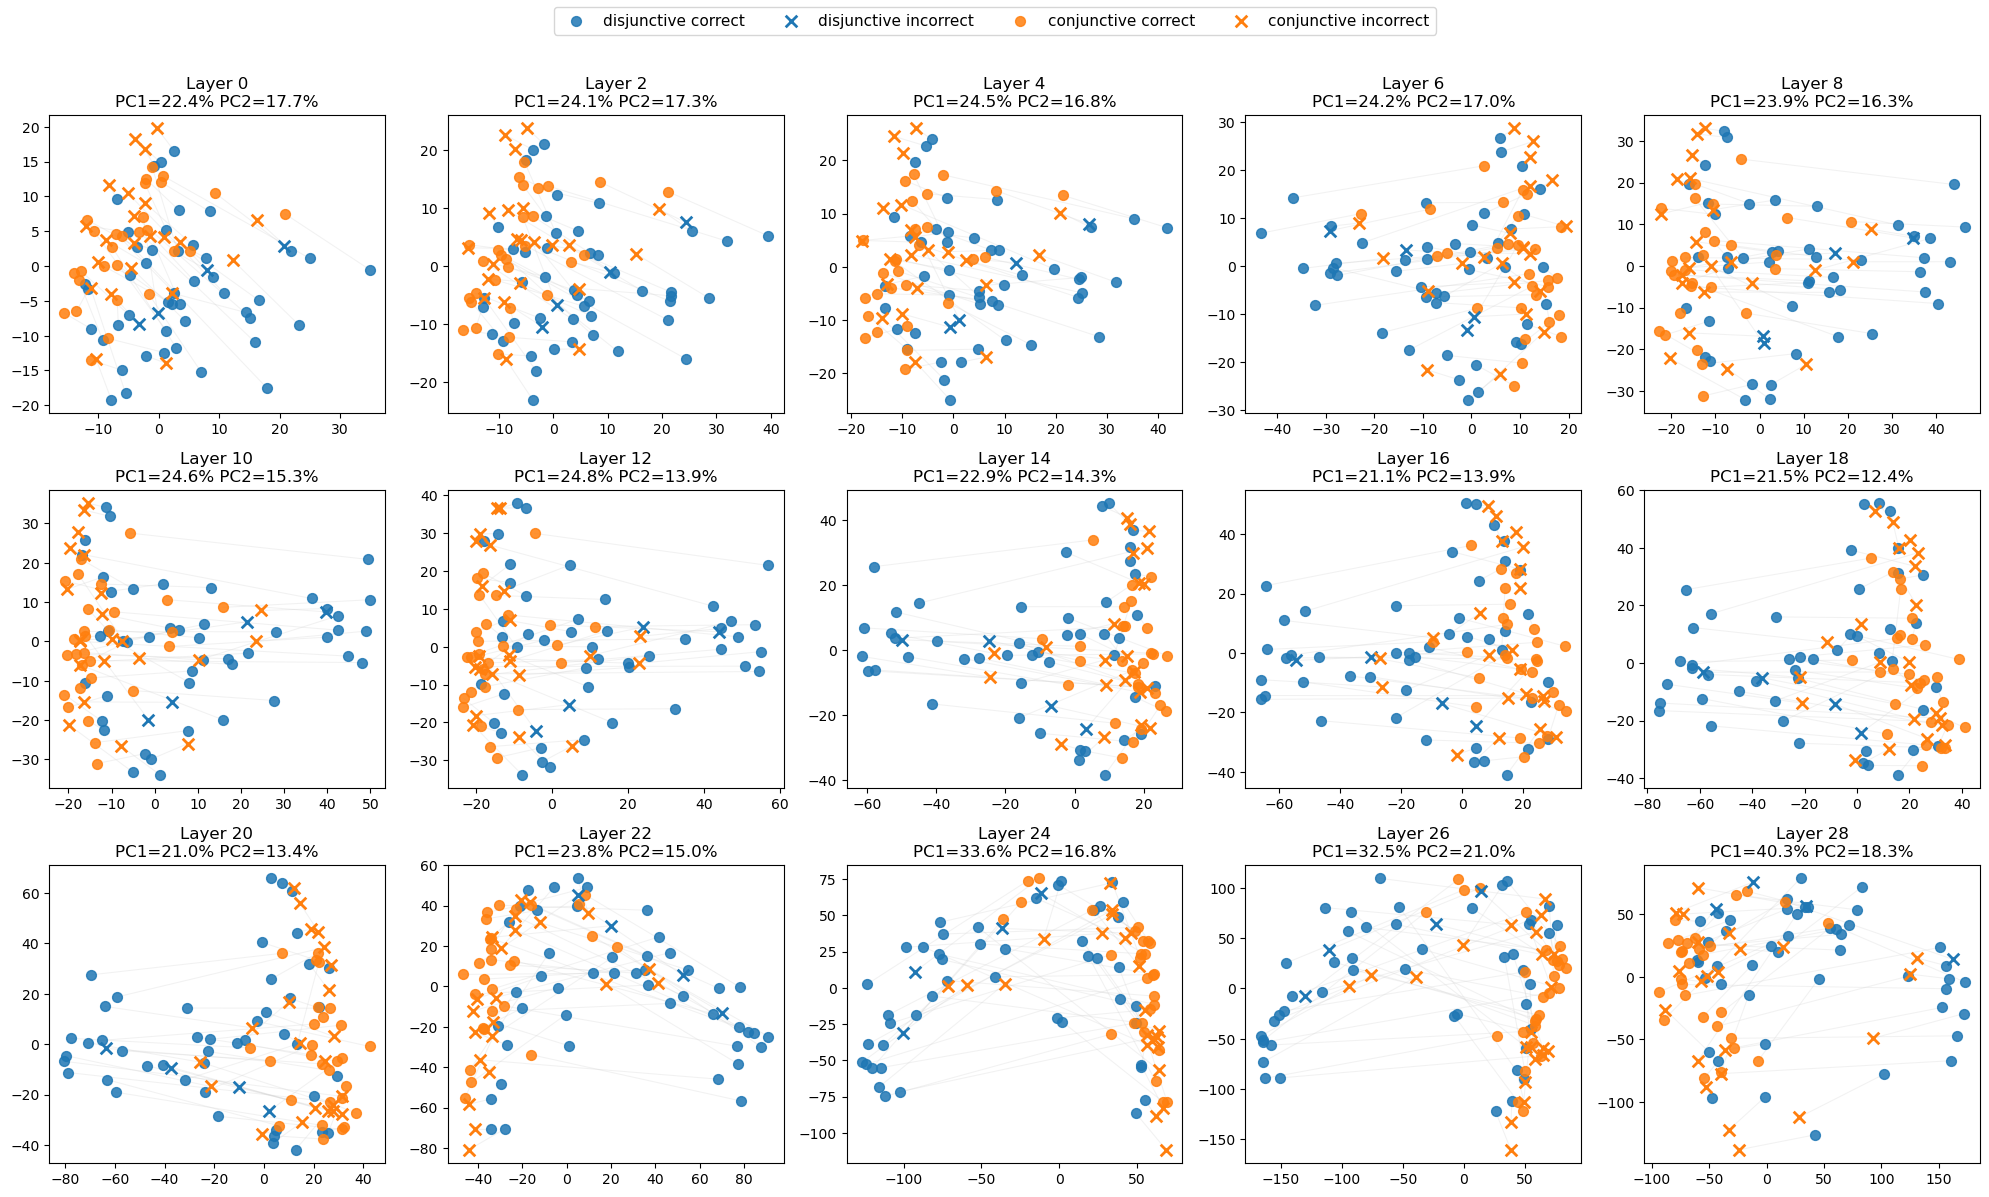

In [4]:



results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# --------------------------------------------------
# FILTER TO 15 DISTRACTORS
# --------------------------------------------------

ND = 20

mask = (
    data["num_distractors"].numpy()
    == ND
)

conditions = np.array(
    data["conditions"]
)[mask]

trials = (
    data["trials"]
    .numpy()[mask]
)

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    lookup[
        (
            c,
            ND,
            int(t),
        )
    ]
    for c, t in zip(
        conditions,
        trials,
    )
])


n_layers = data[
    "bbox_mean_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()



for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "condition": conditions,
        "trial": trials,
        "correct": correct,
    })

    # ----------------------------------------------
    # paired lines
    # ----------------------------------------------

    pivot = (
        df.pivot(
            index="trial",
            columns="condition",
            values=["pc1", "pc2"],
        )
    )

    for trial in pivot.index:

        try:

            x1 = pivot.loc[
                trial,
                ("pc1", "disjunctive")
            ]
            y1 = pivot.loc[
                trial,
                ("pc2", "disjunctive")
            ]

            x2 = pivot.loc[
                trial,
                ("pc1", "conjunctive")
            ]
            y2 = pivot.loc[
                trial,
                ("pc2", "conjunctive")
            ]

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="lightgray",
                alpha=0.3,
                linewidth=0.75,
                zorder=1,
            )

        except KeyError:
            pass

    # ----------------------------------------------
    # CORRECT = circles
    # INCORRECT = x
    # color by condition
    # ----------------------------------------------

    colors = {
        "disjunctive": "C0",
        "conjunctive": "C1",
    }

    for condition in [
        "disjunctive",
        "conjunctive",
    ]:

        sub = df[
            df["condition"]
            == condition
        ]

        # correct
        m = sub["correct"]

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            s=50,
            marker="o",
            color=colors[condition],
            alpha=0.85,
            label=f"{condition} correct"
            if layer == 0 else None,
            zorder=3,
        )

        # incorrect
        ax.scatter(
            sub.loc[~m, "pc1"],
            sub.loc[~m, "pc2"],
            s=70,
            marker="x",
            linewidth=2,
            color=colors[condition],
            alpha=1.0,
            label=f"{condition} incorrect"
            if layer == 0 else None,
            zorder=4,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# --------------------------------------------------
# REMOVE UNUSED AXES
# --------------------------------------------------

for ax in axes[len(layers):]:
    ax.axis("off")

# --------------------------------------------------
# LEGEND
# --------------------------------------------------

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

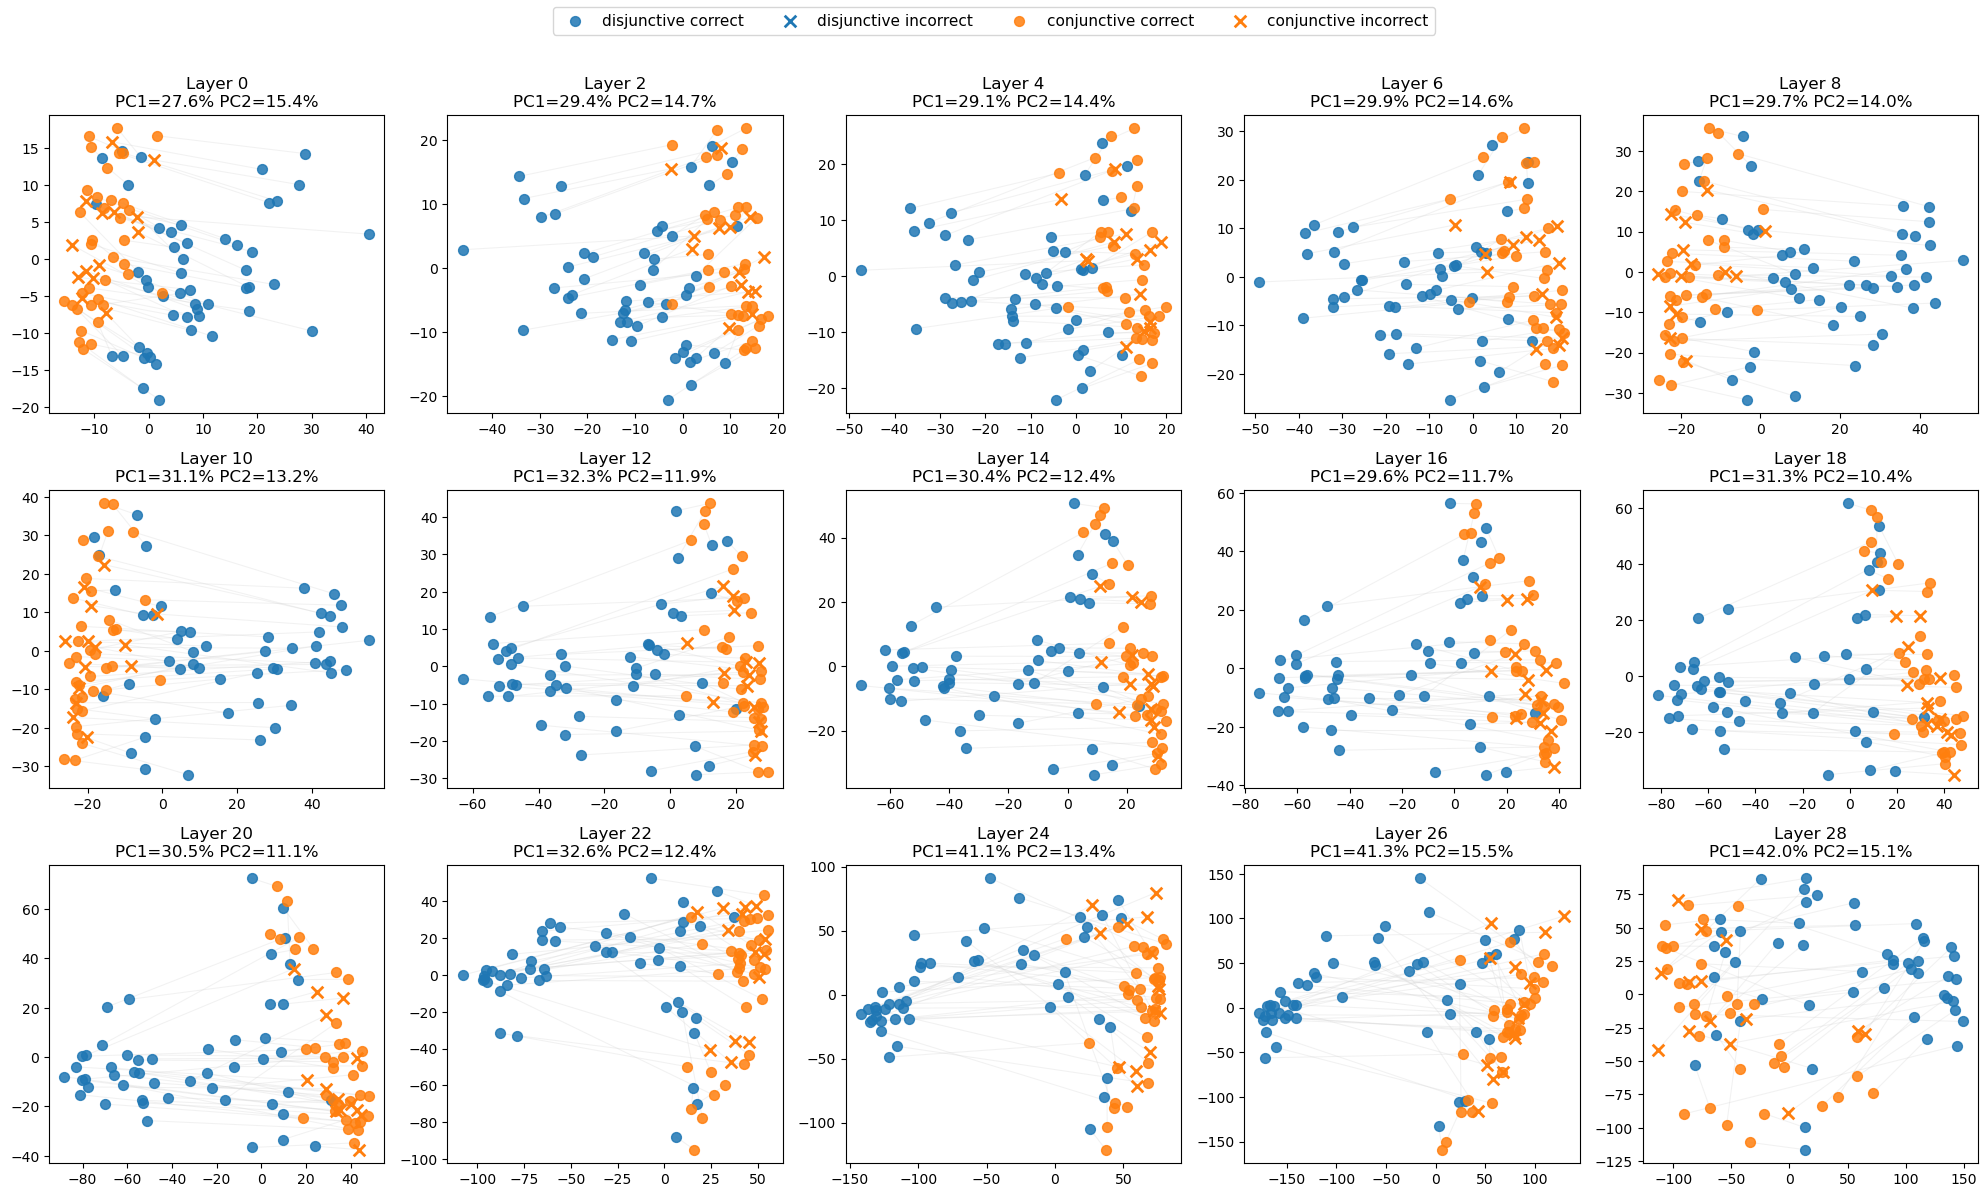

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# --------------------------------------------------
# LOAD BENCHMARK RESULTS
# --------------------------------------------------

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/benchmark_binary_5_to_50.csv"
)

# --------------------------------------------------
# FILTER TO 15 DISTRACTORS
# --------------------------------------------------

ND = 40

mask = (
    data["num_distractors"].numpy()
    == ND
)

conditions = np.array(
    data["conditions"]
)[mask]

trials = (
    data["trials"]
    .numpy()[mask]
)

# --------------------------------------------------
# LOOKUP CORRECTNESS
# --------------------------------------------------

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    lookup[
        (
            c,
            ND,
            int(t),
        )
    ]
    for c, t in zip(
        conditions,
        trials,
    )
])

# --------------------------------------------------
# LAYERS
# --------------------------------------------------

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# --------------------------------------------------
# PCA PER LAYER
# --------------------------------------------------

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "condition": conditions,
        "trial": trials,
        "correct": correct,
    })

    # ----------------------------------------------
    # paired lines
    # ----------------------------------------------

    pivot = (
        df.pivot(
            index="trial",
            columns="condition",
            values=["pc1", "pc2"],
        )
    )

    for trial in pivot.index:

        try:

            x1 = pivot.loc[
                trial,
                ("pc1", "disjunctive")
            ]
            y1 = pivot.loc[
                trial,
                ("pc2", "disjunctive")
            ]

            x2 = pivot.loc[
                trial,
                ("pc1", "conjunctive")
            ]
            y2 = pivot.loc[
                trial,
                ("pc2", "conjunctive")
            ]

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="lightgray",
                alpha=0.3,
                linewidth=0.75,
                zorder=1,
            )

        except KeyError:
            pass

    # ----------------------------------------------
    # CORRECT = circles
    # INCORRECT = x
    # color by condition
    # ----------------------------------------------

    colors = {
        "disjunctive": "C0",
        "conjunctive": "C1",
    }

    for condition in [
        "disjunctive",
        "conjunctive",
    ]:

        sub = df[
            df["condition"]
            == condition
        ]

        # correct
        m = sub["correct"]

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            s=50,
            marker="o",
            color=colors[condition],
            alpha=0.85,
            label=f"{condition} correct"
            if layer == 0 else None,
            zorder=3,
        )

        # incorrect
        ax.scatter(
            sub.loc[~m, "pc1"],
            sub.loc[~m, "pc2"],
            s=70,
            marker="x",
            linewidth=2,
            color=colors[condition],
            alpha=1.0,
            label=f"{condition} incorrect"
            if layer == 0 else None,
            zorder=4,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# --------------------------------------------------
# REMOVE UNUSED AXES
# --------------------------------------------------

for ax in axes[len(layers):]:
    ax.axis("off")

# --------------------------------------------------
# LEGEND
# --------------------------------------------------

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

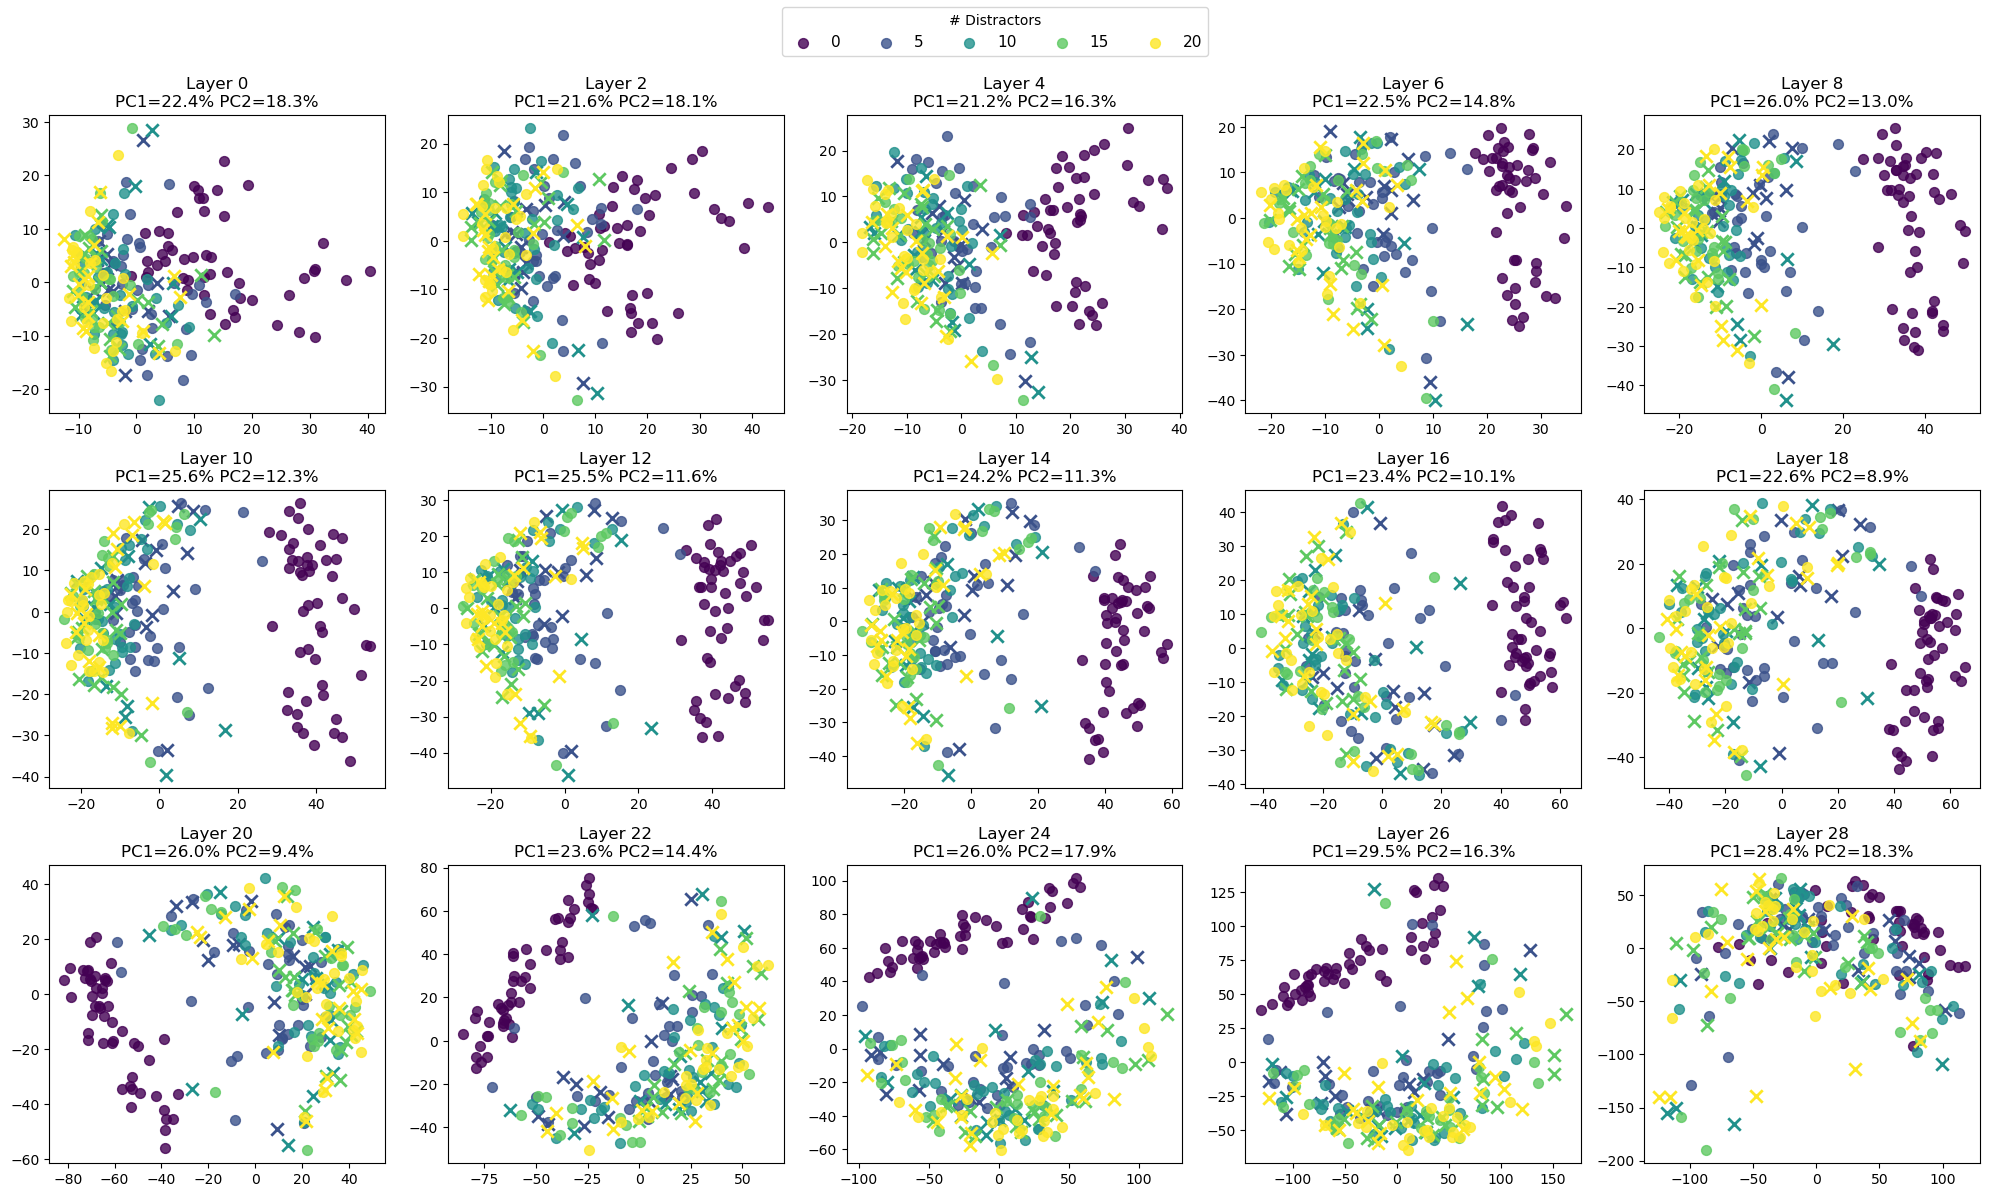

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO CONJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "conjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "conjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

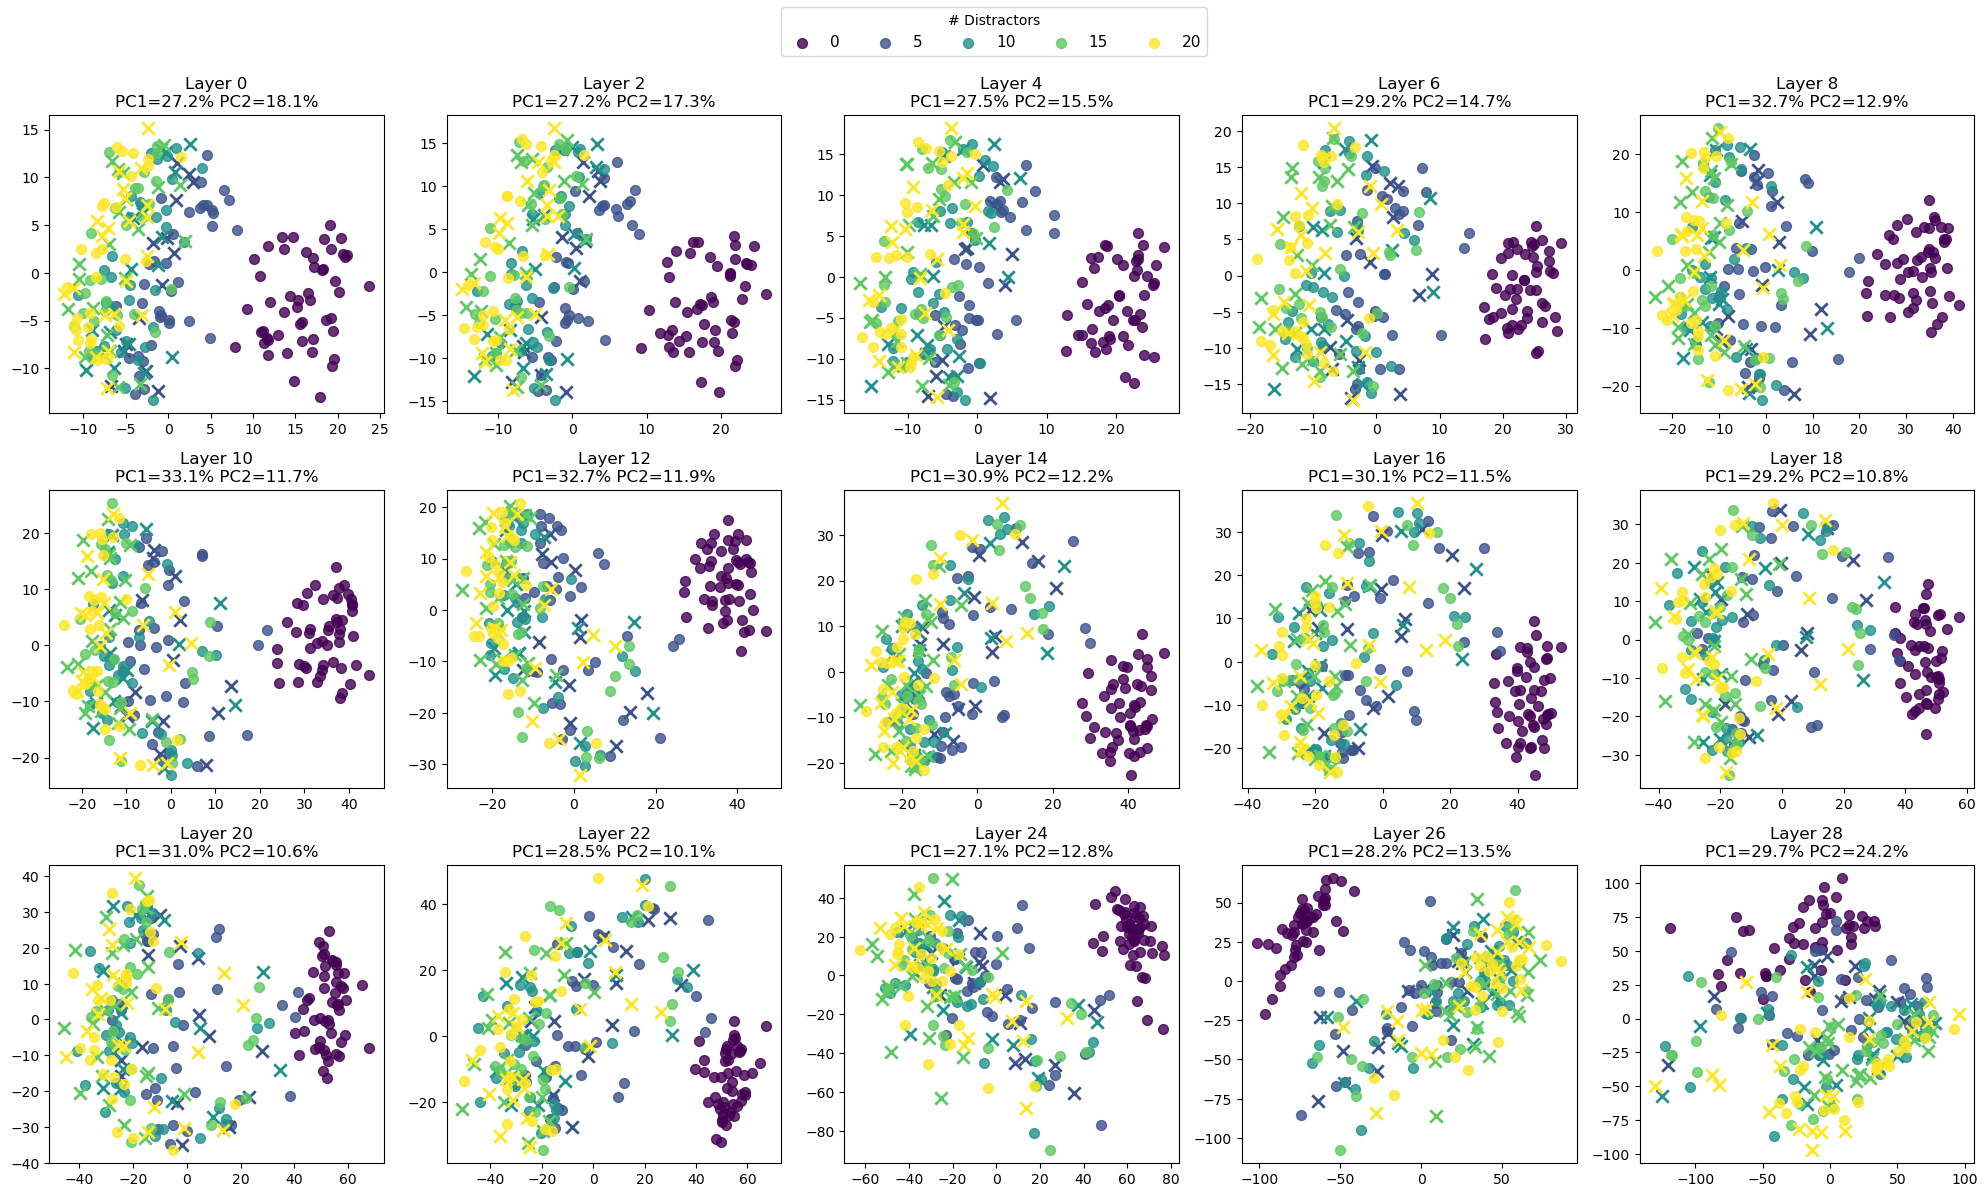

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO CONJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "conjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "conjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "bbox_mean_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

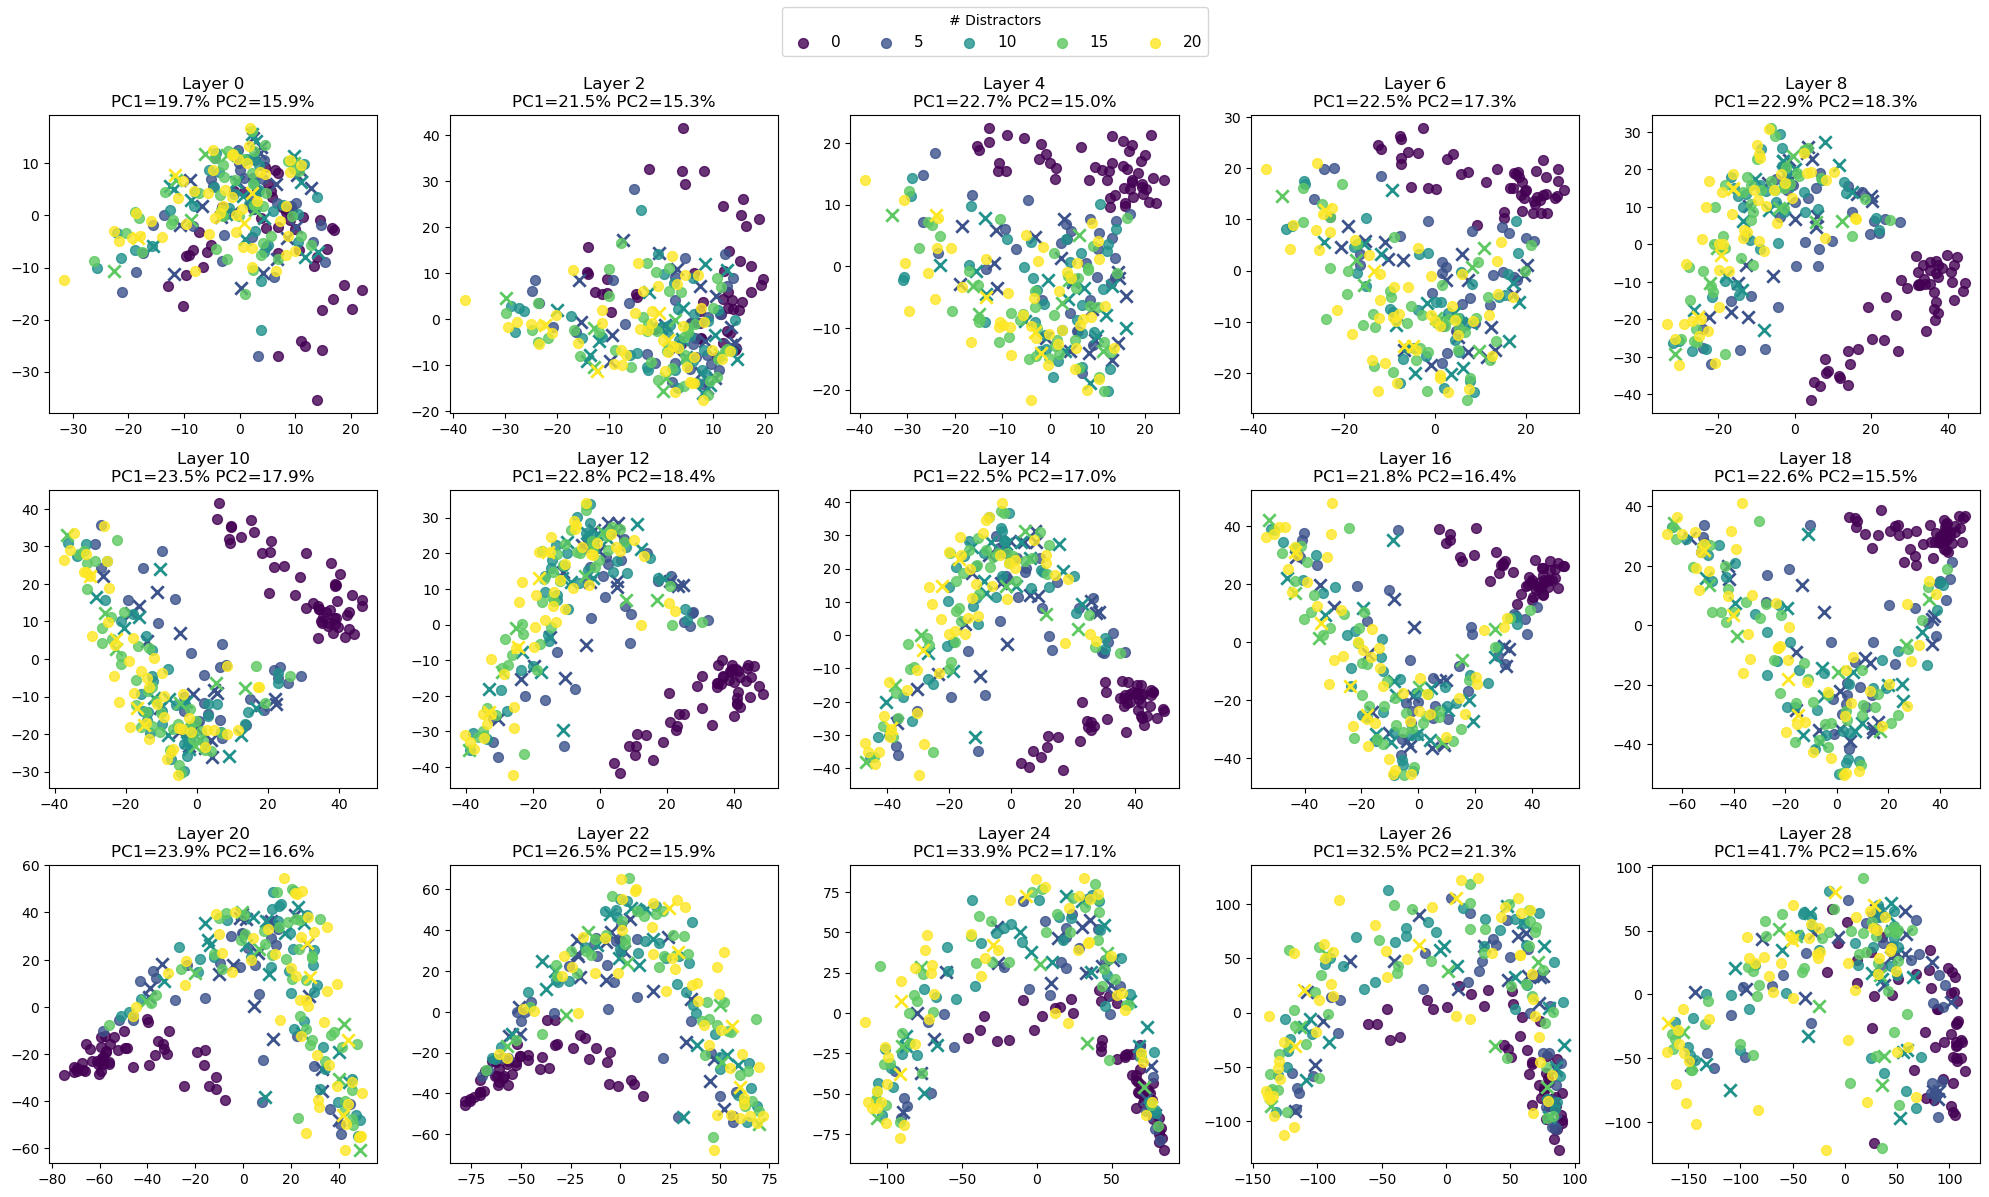

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO DISJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "disjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "disjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

# Similarity analysis

Hidden shape: (50, 29, 3584)
Examples: 50

Correctness:
Correct:   36
Incorrect: 14
Accuracy:  0.72
Layer 0
Layer 1
Layer 2
Layer 3
Layer 4
Layer 5
Layer 6
Layer 7
Layer 8
Layer 9
Layer 10
Layer 11
Layer 12
Layer 13
Layer 14
Layer 15
Layer 16
Layer 17
Layer 18
Layer 19
Layer 20
Layer 21
Layer 22
Layer 23
Layer 24
Layer 25
Layer 26
Layer 27
Layer 28

Best PC per layer:
 layer  pc  predictive_auc  explained_variance
     0   6        0.736111            0.043127
     1   7        0.724206            0.040183
     2   7        0.740079            0.040025
     3  33        0.738095            0.002496
     4  32        0.722222            0.002695
     5   8        0.724206            0.030596
     6  20        0.763889            0.006981
     7  31        0.751984            0.002974
     8  34        0.698413            0.002496
     9   9        0.724206            0.030113
    10  15        0.805556            0.012095
    11  14        0.718254            0.013070
    12  31        

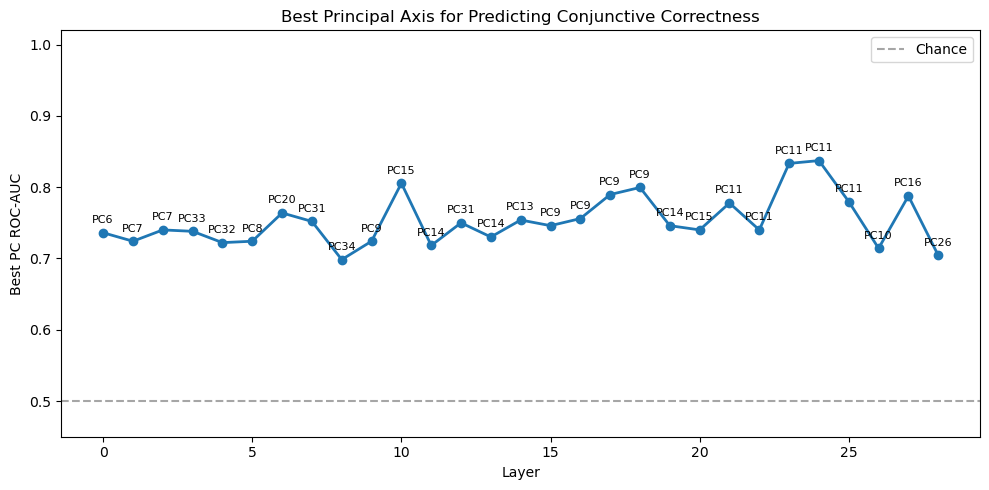

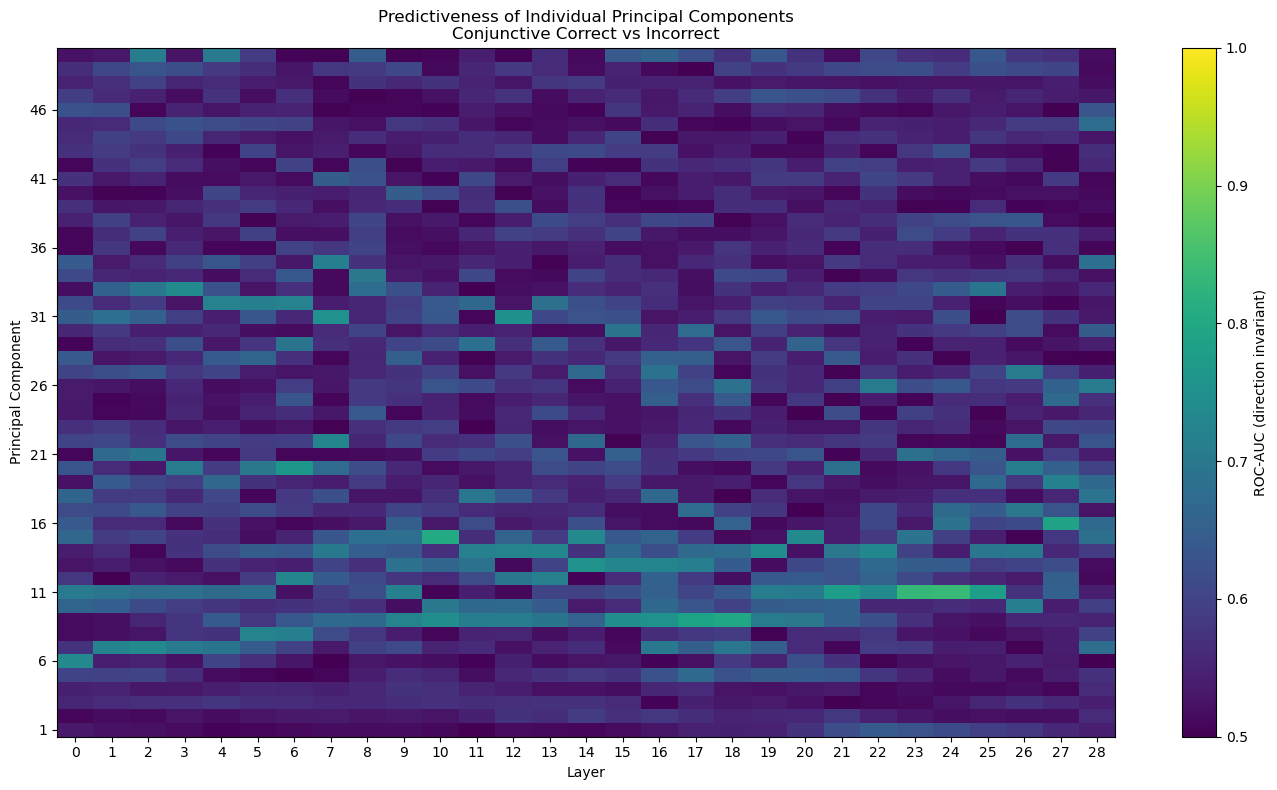

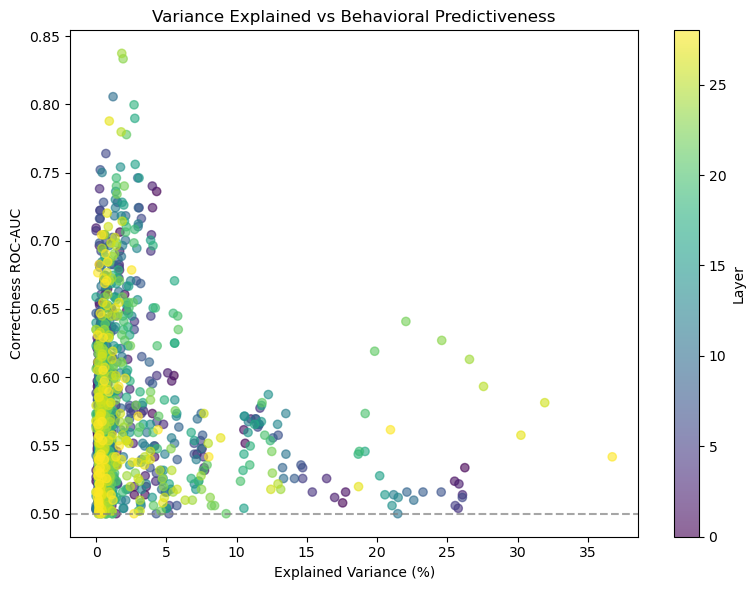

In [12]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

# ==========================================================
# LOAD BENCHMARK RESULTS
# ==========================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "benchmark_binary_5_to_50.csv"
)

# ==========================================================
# SETTINGS
# ==========================================================

ND = 40

# Number of PCs to evaluate.
# Increase if you want to search deeper into the PCA basis.
N_PCS = 50

# ==========================================================
# FILTER TO CONJUNCTIVE, 40 DISTRACTORS
# ==========================================================

conditions_all = np.array(data["conditions"])
distractors_all = data["num_distractors"].numpy()
trials_all = data["trials"].numpy()

mask = (
    (distractors_all == ND)
    & (conditions_all == "conjunctive")
)

trials = trials_all[mask]

hidden = (
    data["center_token_hidden"][mask]
    .float()
    .numpy()
)

print("Hidden shape:", hidden.shape)
print("Examples:", len(trials))

# ==========================================================
# LOOK UP CORRECTNESS
# ==========================================================

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    bool(
        lookup[
            (
                "conjunctive",
                ND,
                int(trial),
            )
        ]
    )
    for trial in trials
])

print("\nCorrectness:")
print("Correct:  ", correct.sum())
print("Incorrect:", (~correct).sum())
print("Accuracy: ", correct.mean())

# Convert to 0/1
y = correct.astype(int)

# ==========================================================
# PCA + PREDICTIVENESS PER LAYER
# ==========================================================

n_layers = hidden.shape[1]

rows = []

for layer in range(n_layers):

    print(f"Layer {layer}")

    X = hidden[:, layer, :]

    # Cannot have more PCs than examples/features
    n_components = min(
        N_PCS,
        X.shape[0],
        X.shape[1],
    )

    pca = PCA(
        n_components=n_components
    )

    X_pca = pca.fit_transform(X)

    # ------------------------------------------------------
    # Evaluate every PC independently
    # ------------------------------------------------------

    for pc in range(n_components):

        values = X_pca[:, pc]

        auc = roc_auc_score(
            y,
            values,
        )

        # PCA sign is arbitrary, so make score
        # direction invariant.
        predictive_auc = max(
            auc,
            1 - auc,
        )

        rows.append({
            "layer": layer,
            "pc": pc + 1,
            "auc": auc,
            "predictive_auc": predictive_auc,
            "explained_variance": (
                pca.explained_variance_ratio_[pc]
            ),
        })

pc_df = pd.DataFrame(rows)

# ==========================================================
# BEST PC PER LAYER
# ==========================================================

best_df = (
    pc_df
    .sort_values(
        "predictive_auc",
        ascending=False,
    )
    .groupby("layer")
    .first()
    .reset_index()
)

print("\nBest PC per layer:")
print(
    best_df[
        [
            "layer",
            "pc",
            "predictive_auc",
            "explained_variance",
        ]
    ].to_string(index=False)
)

# ==========================================================
# PLOT 1
#
# BEST PRINCIPAL AXIS AT EACH LAYER
# ==========================================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    best_df["layer"],
    best_df["predictive_auc"],
    marker="o",
    linewidth=2,
)

ax.axhline(
    0.5,
    linestyle="--",
    color="gray",
    alpha=0.7,
    label="Chance",
)

ax.set_ylim(
    0.45,
    1.02,
)

ax.set_xlabel("Layer")
ax.set_ylabel("Best PC ROC-AUC")

ax.set_title(
    "Best Principal Axis for Predicting "
    "Conjunctive Correctness"
)

# Label which PC won
for _, row in best_df.iterrows():

    ax.annotate(
        f"PC{int(row['pc'])}",
        (
            row["layer"],
            row["predictive_auc"],
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

ax.legend()

plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 2
#
# HEATMAP: PC × LAYER
# ==========================================================

heatmap = pc_df.pivot(
    index="pc",
    columns="layer",
    values="predictive_auc",
)

fig, ax = plt.subplots(
    figsize=(14, 8)
)

im = ax.imshow(
    heatmap.values,
    aspect="auto",
    origin="lower",
    vmin=0.5,
    vmax=1.0,
    cmap="viridis",
)

ax.set_xlabel("Layer")
ax.set_ylabel("Principal Component")

ax.set_xticks(
    np.arange(len(heatmap.columns))
)

ax.set_xticklabels(
    heatmap.columns
)

# Don't necessarily label every PC if there are many
ytick_positions = np.arange(
    0,
    len(heatmap.index),
    5,
)

ax.set_yticks(
    ytick_positions
)

ax.set_yticklabels(
    heatmap.index[ytick_positions]
)

ax.set_title(
    "Predictiveness of Individual Principal Components\n"
    "Conjunctive Correct vs Incorrect"
)

cbar = fig.colorbar(
    im,
    ax=ax,
)

cbar.set_label(
    "ROC-AUC (direction invariant)"
)

plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 3
#
# EXPLAINED VARIANCE VS PREDICTIVENESS
# ==========================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

sc = ax.scatter(
    pc_df["explained_variance"] * 100,
    pc_df["predictive_auc"],
    c=pc_df["layer"],
    alpha=0.6,
)

ax.axhline(
    0.5,
    linestyle="--",
    color="gray",
    alpha=0.7,
)

ax.set_xlabel(
    "Explained Variance (%)"
)

ax.set_ylabel(
    "Correctness ROC-AUC"
)

ax.set_title(
    "Variance Explained vs "
    "Behavioral Predictiveness"
)

cbar = plt.colorbar(
    sc,
    ax=ax,
)

cbar.set_label("Layer")

plt.tight_layout()
plt.show()

In [11]:
print(results_df.columns.tolist())

['condition', 'num_distractors', 'correct']


Hidden shape: (50, 29, 3584)
Examples: 50

Correctness:
Correct:   32
Incorrect: 18
Accuracy:  0.64
Layer 0
Layer 1
Layer 2
Layer 3
Layer 4
Layer 5
Layer 6
Layer 7
Layer 8
Layer 9
Layer 10
Layer 11
Layer 12
Layer 13
Layer 14
Layer 15
Layer 16
Layer 17
Layer 18
Layer 19
Layer 20
Layer 21
Layer 22
Layer 23
Layer 24
Layer 25
Layer 26
Layer 27
Layer 28


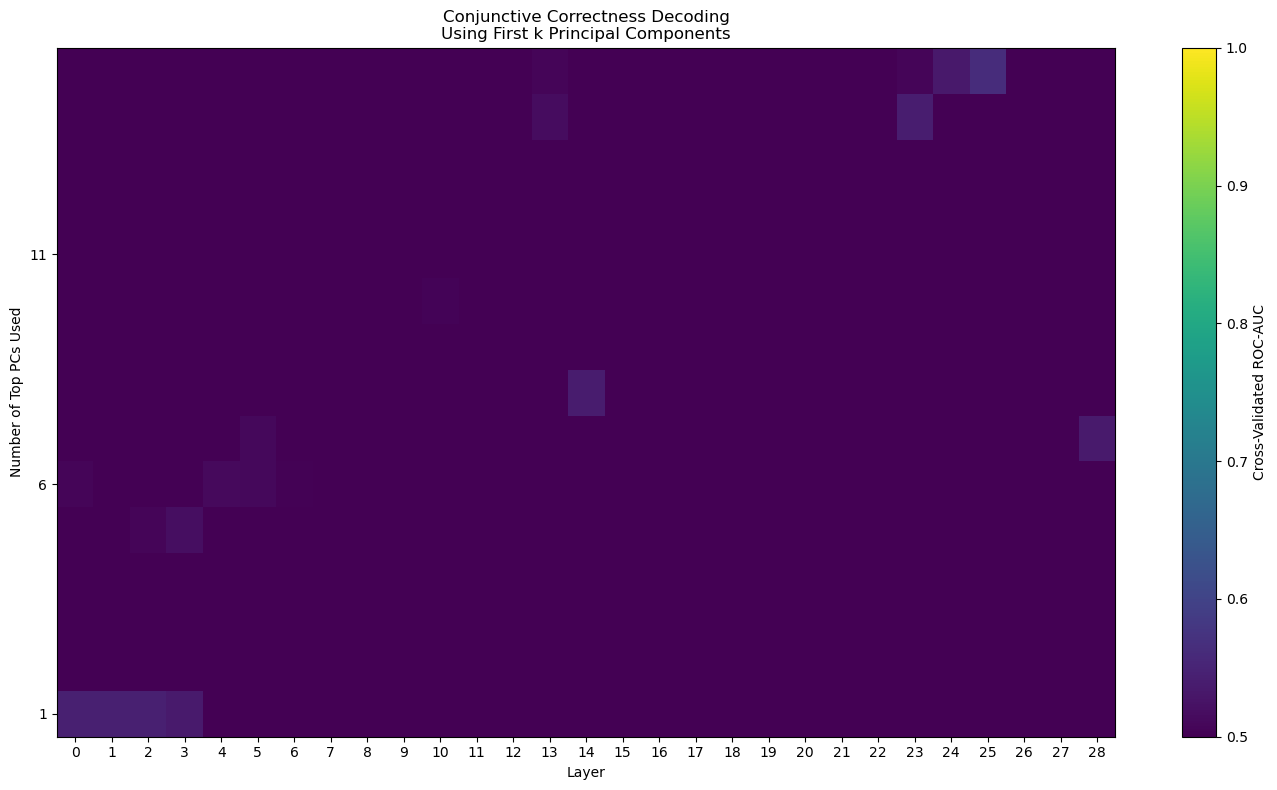

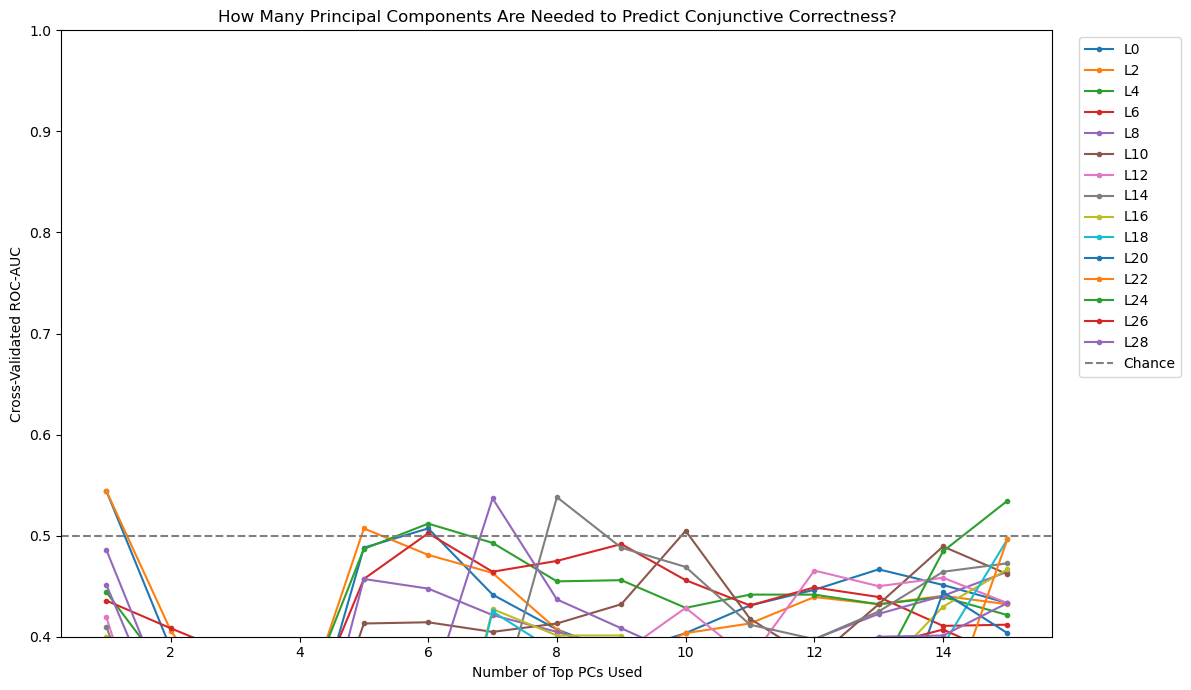

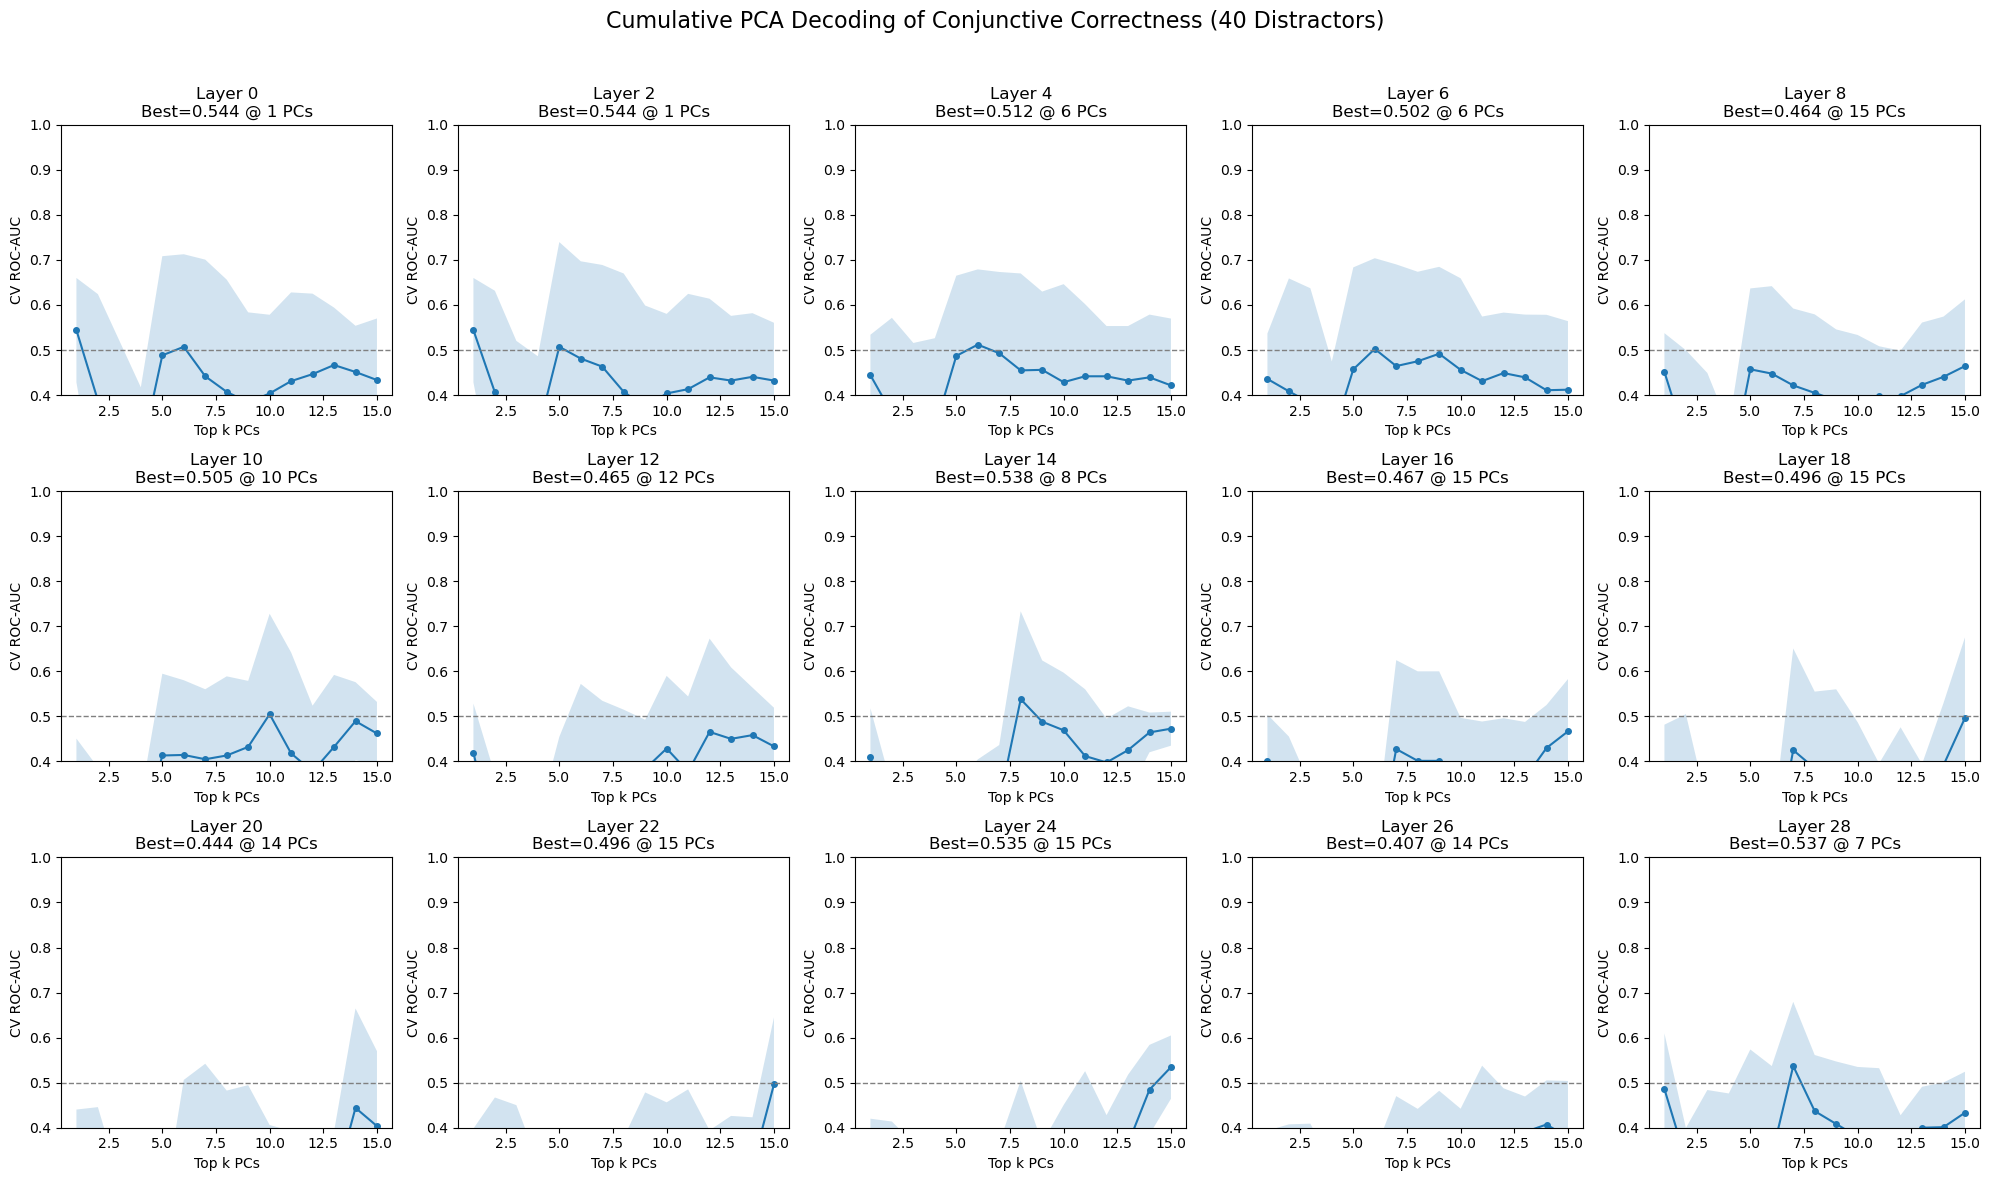


Best number of PCs per layer:
 layer  n_pcs  mean_auc  cumulative_variance
     0      1  0.544048             0.262497
     1      1  0.544048             0.255222
     2      1  0.544048             0.258311
     3      1  0.535714             0.260812
     4      6  0.511905             0.697436
     5      6  0.510714             0.688627
     6      6  0.502381             0.687450
     7     14  0.491667             0.868306
     8     15  0.464286             0.876412
     9     14  0.494048             0.839344
    10     10  0.504762             0.771768
    11     12  0.485714             0.804180
    12     12  0.465476             0.792811
    13     14  0.516667             0.823330
    14      8  0.538095             0.686364
    15     15  0.477381             0.823542
    16     15  0.466667             0.815938
    17      7  0.461905             0.625675
    18     15  0.496429             0.789809
    19     15  0.472619             0.803452
    20     14  0.444048 

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# ==========================================================
# LOAD BENCHMARK RESULTS
# ==========================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "qwen_search_results_counterfactual.csv"
)

# ==========================================================
# SETTINGS
# ==========================================================

ND = 40

# Evaluate PC1, PC1-2, ..., PC1-N_PCS
N_PCS = 50

# Cross-validation folds
N_FOLDS = 5

# ==========================================================
# FILTER TO CONJUNCTIVE, 40 DISTRACTORS
# ==========================================================

conditions_all = np.array(data["conditions"])
distractors_all = data["num_distractors"].numpy()
trials_all = data["trials"].numpy()

mask = (
    (distractors_all == ND)
    & (conditions_all == "conjunctive")
)

trials = trials_all[mask]

hidden = (
    data["center_token_hidden"][mask]
    .float()
    .numpy()
)

print("Hidden shape:", hidden.shape)
print("Examples:", len(trials))

# ==========================================================
# LOOK UP CORRECTNESS
# ==========================================================

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    bool(
        lookup[
            (
                "conjunctive",
                ND,
                int(trial),
            )
        ]
    )
    for trial in trials
])

y = correct.astype(int)

print("\nCorrectness:")
print("Correct:  ", correct.sum())
print("Incorrect:", (~correct).sum())
print("Accuracy: ", correct.mean())

# ==========================================================
# CROSS-VALIDATION
# ==========================================================

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42,
)

# ==========================================================
# PCA + CUMULATIVE PC DECODING
# ==========================================================

n_layers = hidden.shape[1]

rows = []

for layer in range(n_layers):

    print(f"Layer {layer}")

    X = hidden[:, layer, :]

    n_components = min(
        N_PCS,
        X.shape[0],
        X.shape[1],
    )

    # ------------------------------------------------------
    # PCA
    # ------------------------------------------------------

    pca = PCA(
        n_components=n_components
    )

    X_pca = pca.fit_transform(X)

    cumulative_variance = np.cumsum(
        pca.explained_variance_ratio_
    )

    # ------------------------------------------------------
    # First 1 PC
    # First 2 PCs
    # First 3 PCs
    # ...
    # ------------------------------------------------------

    for k in range(
        1,
        min(16,n_components + 1),
    ):

        X_k = X_pca[:, :k]

        clf = LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
        )

        scores = cross_val_score(
            clf,
            X_k,
            y,
            cv=cv,
            scoring="roc_auc",
        )

        rows.append({
            "layer": layer,
            "n_pcs": k,
            "mean_auc": scores.mean(),
            "std_auc": scores.std(),
            "cumulative_variance": (
                cumulative_variance[k - 1]
            ),
        })

results = pd.DataFrame(rows)

# ==========================================================
# PLOT 1
#
# HEATMAP:
# NUMBER OF PCs × LAYER
# ==========================================================

heatmap = results.pivot(
    index="n_pcs",
    columns="layer",
    values="mean_auc",
)

fig, ax = plt.subplots(
    figsize=(14, 8)
)

im = ax.imshow(
    heatmap.values,
    aspect="auto",
    origin="lower",
    vmin=0.5,
    vmax=1.0,
    cmap="viridis",
)

ax.set_xlabel("Layer")
ax.set_ylabel("Number of Top PCs Used")

ax.set_xticks(
    np.arange(len(heatmap.columns))
)

ax.set_xticklabels(
    heatmap.columns
)

# Label every 5 PCs
ytick_positions = np.arange(
    0,
    len(heatmap.index),
    5,
)

ax.set_yticks(
    ytick_positions
)

ax.set_yticklabels(
    heatmap.index[ytick_positions]
)

ax.set_title(
    "Conjunctive Correctness Decoding\n"
    "Using First k Principal Components"
)

cbar = fig.colorbar(
    im,
    ax=ax,
)

cbar.set_label(
    "Cross-Validated ROC-AUC"
)

plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 2
#
# AUC VS NUMBER OF PCs
# SELECTED LAYERS
# ==========================================================

selected_layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

for layer in selected_layers:

    sub = results[
        results["layer"] == layer
    ]

    ax.plot(
        sub["n_pcs"],
        sub["mean_auc"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=f"L{layer}",
    )

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Chance",
)

ax.set_xlabel(
    "Number of Top PCs Used"
)

ax.set_ylabel(
    "Cross-Validated ROC-AUC"
)

ax.set_title(
    "How Many Principal Components Are Needed "
    "to Predict Conjunctive Correctness?"
)

ax.set_ylim(
    0.4,
    1.0,
)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 3
#
# ONE PANEL PER LAYER
# ==========================================================

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

for ax, layer in zip(
    axes,
    layers,
):

    sub = results[
        results["layer"] == layer
    ]

    ax.plot(
        sub["n_pcs"],
        sub["mean_auc"],
        marker="o",
        markersize=4,
    )

    ax.fill_between(
        sub["n_pcs"],
        sub["mean_auc"] - sub["std_auc"],
        sub["mean_auc"] + sub["std_auc"],
        alpha=0.2,
    )

    ax.axhline(
        0.5,
        color="gray",
        linestyle="--",
        linewidth=1,
    )

    best_idx = (
        sub["mean_auc"]
        .idxmax()
    )

    best = sub.loc[best_idx]

    ax.set_title(
        f"Layer {layer}\n"
        f"Best={best['mean_auc']:.3f} "
        f"@ {int(best['n_pcs'])} PCs"
    )

    ax.set_xlabel(
        "Top k PCs"
    )

    ax.set_ylabel(
        "CV ROC-AUC"
    )

    ax.set_ylim(
        0.4,
        1.0,
    )


# Remove unused axes

for ax in axes[len(layers):]:
    ax.axis("off")


fig.suptitle(
    f"Cumulative PCA Decoding of Conjunctive Correctness "
    f"({ND} Distractors)",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

# ==========================================================
# SUMMARY
# ==========================================================

best_rows = (
    results.loc[
        results.groupby("layer")[
            "mean_auc"
        ].idxmax()
    ]
    .sort_values("layer")
)

print("\nBest number of PCs per layer:")

print(
    best_rows[
        [
            "layer",
            "n_pcs",
            "mean_auc",
            "cumulative_variance",
        ]
    ].to_string(index=False)
)